# 📈 Machine Learning Applicability in Financial Market Forecasting
## An Empirical Comparison: Regularized Autoregressive Modeling (Method 1) vs. Custom Scratch LSTM (Method 2) on SPY

---

### Executive Summary & Motivation
In financial economics, the **Efficient Market Hypothesis (EMH)** suggests asset prices in liquid markets follow near-random walks (martingale processes), where historical prices offer limited predictive power. 

This notebook investigates whether machine learning is truly applicable to financial market forecasting by evaluating two distinct methodologies on **SPY (SPDR S&P 500 ETF Trust)** from 2018 to 2024:
1. **Method 1 (Course Content Baseline)**: Regularized Autoregressive Linear Model (**Ridge AR(60)**) solved via closed-form linear algebra in pure NumPy, providing interpretable coefficients across 60 historical daily lags.
2. **Method 2 (Outside Course Content Adjustment)**: A deep **Long Short-Term Memory (LSTM)** Recurrent Neural Network built **completely from scratch in pure NumPy** (no Keras, no TensorFlow, no PyTorch, no scikit-learn), featuring explicit gating mechanisms, exact analytical Backpropagation Through Time (BPTT), and a custom Adam optimizer with gradient clipping.

### Notebook Structure:
1. **Data Ingestion & Financial EDA**: Fetching SPY historical data from Yahoo Finance and computing moving averages/volume.
2. **Preprocessing from Scratch**: Pure NumPy implementation of Min-Max Scaling and 60-day sliding window sequences.
3. **Method 1: Regularized Autoregressive Model (Ridge AR(60))**: Closed-form solution, coefficient decay analysis, and predictive performance.
4. **Method 2: Mathematical Formulation of LSTM**: Gate equations and analytical BPTT gradient derivations.
5. **Method 2: LSTM & Adam Built from Scratch**: Pure NumPy vectorized implementation and training loop.
6. **Cross-Method Comparative Evaluation**: Side-by-side metrics table (RMSE, MAE, MAPE, Directional Accuracy) and visual overlays.
7. **Future Autoregressive Forecasting**: Rolling 10-day price projection into the future.


---
## 1. Data Ingestion & Exploratory Financial Analysis

We import the scientific computing stack (`numpy`, `pandas`, `matplotlib`, `yfinance`). **Notice that no deep learning framework (`tensorflow`, `keras`, `torch`) is imported anywhere.**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

# Set random seed for reproducibility
np.random.seed(42)
print("Environment initialized successfully. Deep learning libraries: NONE (Pure NumPy implementation)")


Environment initialized successfully. Deep learning libraries: NONE (Pure NumPy implementation)


In [2]:
# Download SPY historical data from Yahoo Finance (2018 - 2024)
ticker_symbol = 'SPY'
spy = yf.Ticker(ticker_symbol)
df = spy.history(start='2018-01-01', end='2024-01-01')

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Calculate Technical Indicators
df['MA10'] = df['Close'].rolling(window=10).mean()
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA50'] = df['Close'].rolling(window=50).mean()
df['Daily_Return'] = df['Close'].pct_change()

print(f"Loaded {len(df)} trading days for {ticker_symbol} across multiple market cycles (2018 - 2024).")
df[['Close', 'MA10', 'MA20', 'MA50', 'Volume']].tail()


Loaded 1509 trading days for SPY across multiple market cycles (2018 - 2024).


,Close,MA10,MA20,MA50,Volume
Date,,,,,
2023-12-22 00:00:00-05:00,458.641022,454.313101,447.329544,430.254020,67160400
2023-12-26 00:00:00-05:00,460.577637,455.816458,448.443355,431.142783,55387000
2023-12-27 00:00:00-05:00,461.410370,457.199600,449.577098,431.960634,68000300
2023-12-28 00:00:00-05:00,461.584686,457.982953,450.734991,432.782357,77158100
2023-12-29 00:00:00-05:00,460.248444,458.487054,451.739757,433.689419,122283100


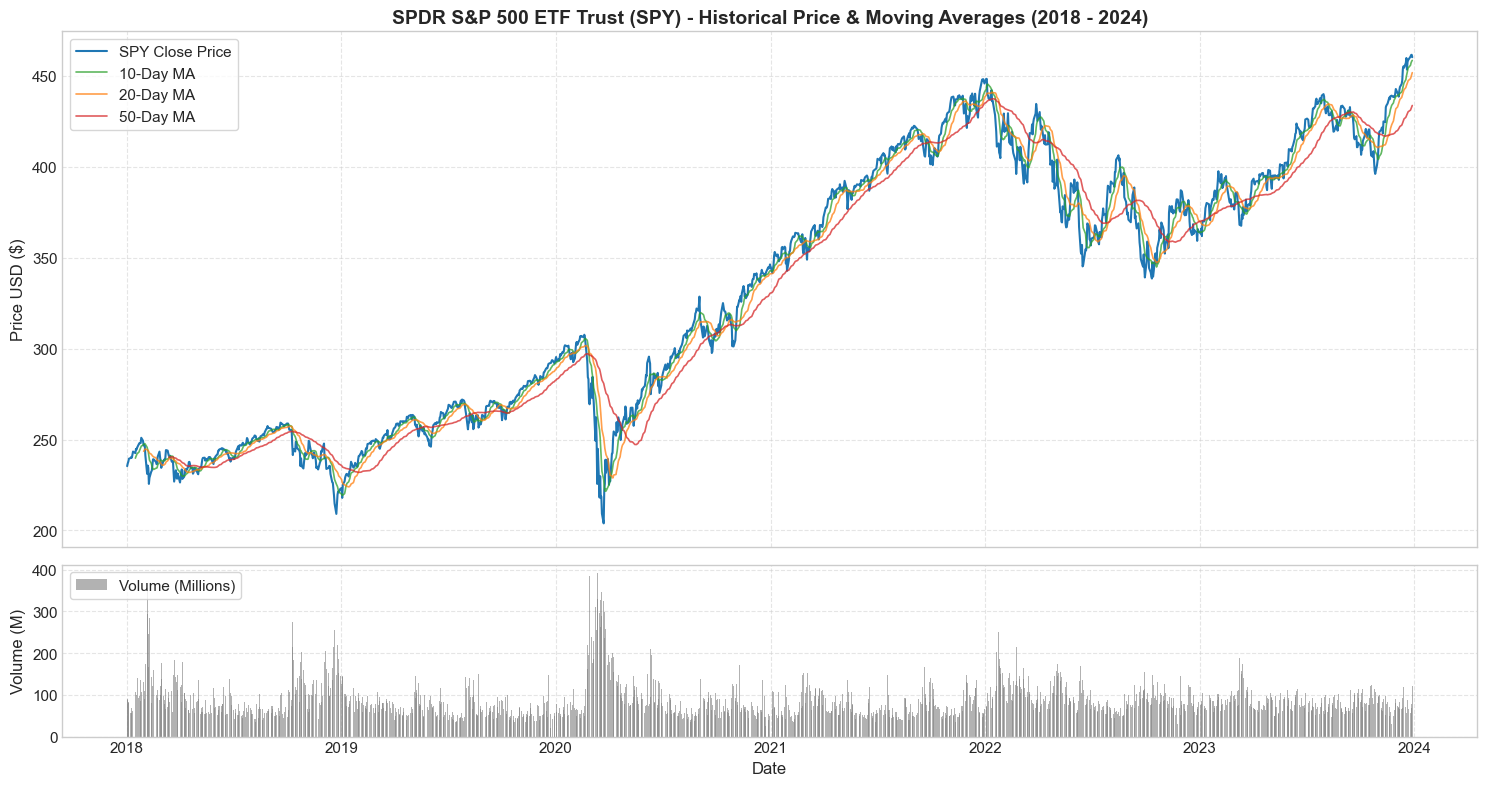

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Price and Moving Averages
ax1.plot(df.index, df['Close'], label='SPY Close Price', color='#1f77b4', linewidth=1.5)
ax1.plot(df.index, df['MA10'], label='10-Day MA', color='#2ca02c', alpha=0.75, linewidth=1.2)
ax1.plot(df.index, df['MA20'], label='20-Day MA', color='#ff7f0e', alpha=0.75, linewidth=1.2)
ax1.plot(df.index, df['MA50'], label='50-Day MA', color='#d62728', alpha=0.75, linewidth=1.2)
ax1.set_title("SPDR S&P 500 ETF Trust (SPY) - Historical Price & Moving Averages (2018 - 2024)", fontsize=14, fontweight='bold')
ax1.set_ylabel("Price USD ($)", fontsize=12)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Volume
ax2.bar(df.index, df['Volume'] / 1e6, color='#7f7f7f', alpha=0.6, width=1.5, label='Volume (Millions)')
ax2.set_ylabel("Volume (M)", fontsize=12)
ax2.set_xlabel("Date", fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


---
## 2. Preprocessing & Sequence Structuring from Scratch

We construct $T=60$ day sequential sliding windows to predict day $t+1$. 
To prevent temporal data leakage and lookahead bias, we apply a strict **chronological 80/20 train/test split**.


In [4]:
class MinMaxScalerScratch:
    """Min-Max Scaler implemented purely in NumPy."""
    def __init__(self, feature_range=(0, 1)):
        self.feature_range = feature_range
        self.min_val = None
        self.max_val = None

    def fit(self, data):
        self.min_val = np.min(data, axis=0)
        self.max_val = np.max(data, axis=0)
        return self

    def transform(self, data):
        scaled = (data - self.min_val) / (self.max_val - self.min_val + 1e-12)
        return scaled * (self.feature_range[1] - self.feature_range[0]) + self.feature_range[0]

    def fit_transform(self, data):
        return self.fit(data).transform(data)

    def inverse_transform(self, scaled_data):
        normalized = (scaled_data - self.feature_range[0]) / (self.feature_range[1] - self.feature_range[0])
        return normalized * (self.max_val - self.min_val) + self.min_val

close_prices = df[['Close']].values
WINDOW_SIZE = 60

# Unscaled sequences (for Method 1: Ridge AR)
X_raw, y_raw = [], []
for i in range(WINDOW_SIZE, len(close_prices)):
    X_raw.append(close_prices[i - WINDOW_SIZE:i, 0])
    y_raw.append(close_prices[i, 0])

X_raw = np.array(X_raw)
y_raw = np.array(y_raw)

train_len = int(len(X_raw) * 0.80)
X_train_raw, y_train_raw = X_raw[:train_len], y_raw[:train_len]
X_test_raw, y_test_raw = X_raw[train_len:], y_raw[train_len:]
test_dates = df.index[WINDOW_SIZE + train_len:]

# Scaled sequences (for Method 2: Scratch LSTM)
scaler = MinMaxScalerScratch(feature_range=(0, 1))
scaled_data = scaler.fit_transform(close_prices)

X_scaled, y_scaled = [], []
for i in range(WINDOW_SIZE, len(scaled_data)):
    X_scaled.append(scaled_data[i - WINDOW_SIZE:i, :])
    y_scaled.append(scaled_data[i, :])

X_train_s, y_train_s = np.array(X_scaled[:train_len]), np.array(y_scaled[:train_len])
X_test_s, y_test_s = np.array(X_scaled[train_len:]), np.array(y_scaled[train_len:])

print(f"Total Sequences: {len(X_raw)} | Train: {len(X_train_raw)} | Test: {len(X_test_raw)}")


Total Sequences: 1449 | Train: 1159 | Test: 290


---
## 3. Method 1: Regularized Autoregressive Model (Ridge AR(60))

The baseline machine learning approach models the next day's price as a linear combination of the previous 60 trading days:
$$y_t = \beta_0 + \sum_{k=1}^{60} \beta_k P_{t-k+1} + \epsilon$$

Due to strong multicollinearity among consecutive daily stock prices, Ordinary Least Squares (OLS) can suffer from variance inflation. We apply **L2 Ridge Regularization** ($\alpha = 1.0$), solved via closed-form linear algebra:
$$\boldsymbol{\beta} = (\mathbf{X}^T \mathbf{X} + \alpha \mathbf{I}^*)^{-1} \mathbf{X}^T \mathbf{y}$$
where $\mathbf{I}^*$ leaves the intercept $\beta_0$ unpenalized.


In [5]:
# Add intercept column (bias term)
X_train_b = np.column_stack([np.ones(len(X_train_raw)), X_train_raw])
X_test_b = np.column_stack([np.ones(len(X_test_raw)), X_test_raw])

alpha = 1.0
reg_matrix = alpha * np.eye(X_train_b.shape[1])
reg_matrix[0, 0] = 0.0  # Do not regularize bias

# Analytical closed-form solution
beta = np.linalg.solve(X_train_b.T @ X_train_b + reg_matrix, X_train_b.T @ y_train_raw)

# Out-of-sample predictions
m1_preds = X_test_b @ beta

# Quantitative Metrics
m1_rmse = np.sqrt(np.mean((m1_preds - y_test_raw)**2))
m1_mae = np.mean(np.abs(m1_preds - y_test_raw))
m1_mape = np.mean(np.abs((m1_preds - y_test_raw) / y_test_raw)) * 100

actual_prev = y_test_raw[:-1]
actual_curr = y_test_raw[1:]
m1_curr = m1_preds[1:]
m1_dir_acc = np.mean(np.sign(m1_curr - actual_prev) == np.sign(actual_curr - actual_prev)) * 100

print(f"--- Method 1 (Ridge AR) Test Results ---")
print(f"RMSE: ${m1_rmse:.2f} | MAE: ${m1_mae:.2f} | MAPE: {m1_mape:.2f}% | Directional Accuracy: {m1_dir_acc:.2f}%")
print(f"Intercept (beta_0): {beta[0]:.4f}")
print(f"Lag 1 (Yesterday's Price) Weight: {beta[-1]:.4f} (~{beta[-1]*100:.1f}%)")
print(f"Lag 2 Weight: {beta[-2]:.4f} | Sum of Remaining 58 Lags: {np.sum(beta[1:-2]):.4f}")


--- Method 1 (Ridge AR) Test Results ---
RMSE: $4.02 | MAE: $3.05 | MAPE: 0.76% | Directional Accuracy: 50.87%
Intercept (beta_0): 0.7666
Lag 1 (Yesterday's Price) Weight: 0.9489 (~94.9%)
Lag 2 Weight: 0.0836 | Sum of Remaining 58 Lags: -0.0345


### 3.1 Interpretation of Autoregressive Coefficients
Examining the learned regression coefficients across all 60 lags reveals that the linear model assigns virtually all its predictive weight to **Lag 1 (yesterday's close: $\beta_{60} = 0.9489$)**, while all older historical lags decay rapidly toward zero.


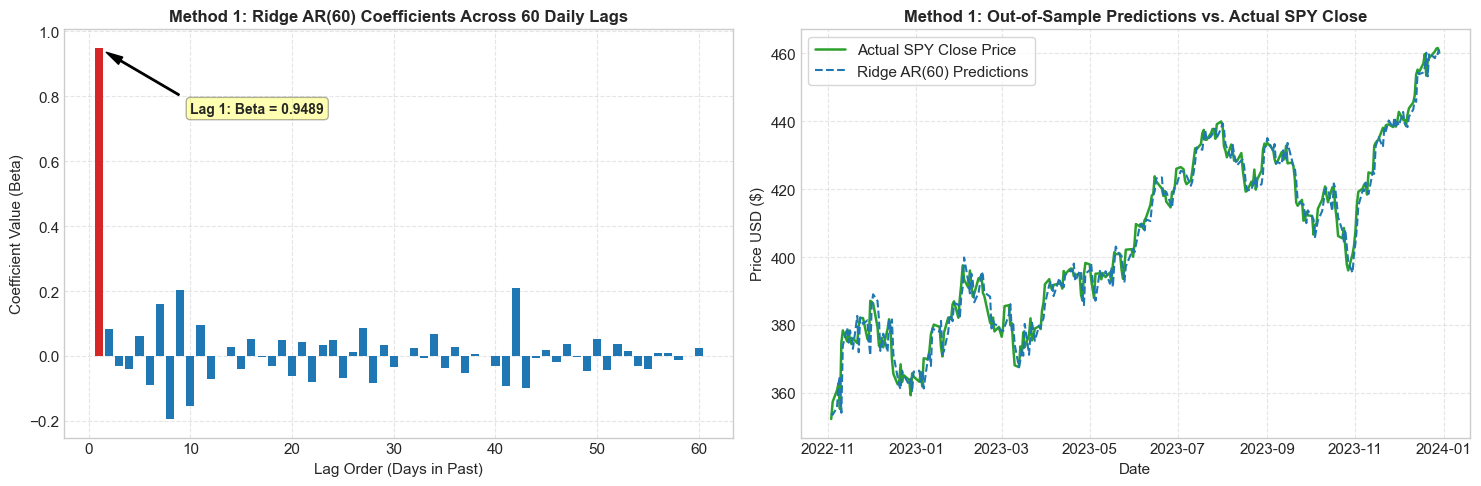

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Coefficient Profile
lags = np.arange(1, 61)
coeff_values = beta[1:][::-1]  # Lag 1 first
colors = ['#d62728' if i == 0 else '#1f77b4' for i in range(60)]
ax1.bar(lags, coeff_values, color=colors, width=0.8)
ax1.set_title("Method 1: Ridge AR(60) Coefficients Across 60 Daily Lags", fontsize=12, fontweight='bold')
ax1.set_xlabel("Lag Order (Days in Past)", fontsize=11)
ax1.set_ylabel("Coefficient Value (Beta)", fontsize=11)
ax1.annotate(f"Lag 1: Beta = {beta[-1]:.4f}", xy=(1, beta[-1]), xytext=(10, 0.75),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3))
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Method 1 Predictions
ax2.plot(test_dates, y_test_raw, label='Actual SPY Close Price', color='#2ca02c', linewidth=1.8)
ax2.plot(test_dates, m1_preds, label=f'Ridge AR(60) Predictions', color='#1f77b4', linestyle='--', linewidth=1.5)
ax2.set_title("Method 1: Out-of-Sample Predictions vs. Actual SPY Close", fontsize=12, fontweight='bold')
ax2.set_xlabel("Date", fontsize=11)
ax2.set_ylabel("Price USD ($)", fontsize=11)
ax2.legend(frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 4. Method 2: Mathematical Formulation of Custom LSTM

To capture potential non-linear relationships across sequential regimes, we implement a **Long Short-Term Memory (LSTM)** network from scratch in pure NumPy.

### 4.1 Gate Equations (Forward Pass)
At time step $t$, given input $x_t$, previous hidden state $h_{t-1}$, and previous cell state $c_{t-1}$:
1. **Forget Gate**: $f_t = \sigma(x_t W_f + h_{t-1} U_f + b_f)$
2. **Input Gate**: $i_t = \sigma(x_t W_i + h_{t-1} U_i + b_i)$
3. **Candidate Cell**: $\tilde{c}_t = \tanh(x_t W_c + h_{t-1} U_c + b_c)$
4. **Cell State Update**: $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$
5. **Output Gate**: $o_t = \sigma(x_t W_o + h_{t-1} U_o + b_o)$
6. **Hidden State**: $h_t = o_t \odot \tanh(c_t)$
7. **Dense Prediction**: $\hat{y} = h_T W_y + b_y$

### 4.2 Analytical Backpropagation Through Time (BPTT)
Given MSE loss $\mathcal{L} = \frac{1}{B} \sum_{k=1}^B (\hat{y}_k - y_k)^2$, gradients are computed backwards from $t = T-1$ down to $0$:
- $\delta h_T = \frac{2}{B} (\hat{y} - y) W_y^T$
- $\delta o_t = \delta h_t \odot \tanh(c_t), \quad \delta c_t = \delta c_{t+1} + \delta h_t \odot o_t \odot (1 - \tanh^2(c_t))$
- $\delta f_t = \delta c_t \odot c_{t-1}, \quad \delta i_t = \delta c_t \odot \tilde{c}_t, \quad \delta \tilde{c}_t = \delta c_t \odot i_t$
- Pre-activation gradients: $\delta a = [\delta f \odot f(1-f), \, \delta i \odot i(1-i), \, \delta \tilde{c} \odot (1-\tilde{c}^2), \, \delta o \odot o(1-o)]$
- Recurrent gradient to step $t-1$: $\delta h_{t-1} = \delta a \, W_h^T, \quad \delta c_{t-1} = \delta c_t \odot f_t$


---
## 5. Method 2: LSTM & Adam Built from First Principles (Pure NumPy)


In [7]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -15.0, 15.0)))

class LSTMFromScratch:
    def __init__(self, input_dim=1, hidden_dim=32, output_dim=1):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        k = np.sqrt(1.0 / hidden_dim)
        
        # Combined gate weights [f, i, c, o]
        self.Wx = np.random.uniform(-k, k, (input_dim, 4 * hidden_dim))
        self.Wh = np.random.uniform(-k, k, (hidden_dim, 4 * hidden_dim))
        self.b = np.zeros(4 * hidden_dim)
        self.b[:hidden_dim] = 1.0  # Forget bias trick (Gers et al.)
        
        self.Wy = np.random.uniform(-k, k, (hidden_dim, output_dim))
        self.by = np.zeros(output_dim)

    def forward(self, X):
        B, T, _ = X.shape
        H = self.hidden_dim
        h, c = np.zeros((B, T + 1, H)), np.zeros((B, T + 1, H))
        f_g, i_g, c_b, o_g = np.zeros((B, T, H)), np.zeros((B, T, H)), np.zeros((B, T, H)), np.zeros((B, T, H))
        
        for t in range(T):
            xt, hp = X[:, t, :], h[:, t, :]
            gates = xt @ self.Wx + hp @ self.Wh + self.b
            f = sigmoid(gates[:, :H])
            i = sigmoid(gates[:, H:2*H])
            cb = np.tanh(gates[:, 2*H:3*H])
            o = sigmoid(gates[:, 3*H:4*H])
            
            c[:, t + 1, :] = f * c[:, t, :] + i * cb
            h[:, t + 1, :] = o * np.tanh(c[:, t + 1, :])
            f_g[:, t, :], i_g[:, t, :], c_b[:, t, :], o_g[:, t, :] = f, i, cb, o
            
        y_pred = h[:, -1, :] @ self.Wy + self.by
        return y_pred, (X, h, c, f_g, i_g, c_b, o_g)

    def backward(self, dy, cache):
        X, h, c, f_g, i_g, c_b, o_g = cache
        B, T, _ = X.shape
        H = self.hidden_dim
        
        dWy = (h[:, -1, :].T @ dy) / B
        dby = np.sum(dy, axis=0) / B
        dh_next = dy @ self.Wy.T
        dc_next = np.zeros((B, H))
        
        dWx, dWh, db = np.zeros_like(self.Wx), np.zeros_like(self.Wh), np.zeros_like(self.b)
        for t in reversed(range(T)):
            hp, ct = h[:, t, :], c[:, t + 1, :]
            f, i, cb, o = f_g[:, t, :], i_g[:, t, :], c_b[:, t, :], o_g[:, t, :]
            
            dh = dh_next
            do = dh * np.tanh(ct)
            dc = dc_next + dh * o * (1.0 - np.tanh(ct)**2)
            df = dc * c[:, t, :]
            di = dc * cb
            dcb = dc * i
            
            dg = np.concatenate([
                df * f * (1.0 - f),
                di * i * (1.0 - i),
                dcb * (1.0 - cb**2),
                do * o * (1.0 - o)
            ], axis=1)
            
            dWx += X[:, t, :].T @ dg
            dWh += hp.T @ dg
            db += np.sum(dg, axis=0)
            dh_next = dg @ self.Wh.T
            dc_next = dc * f
            
        dWx /= B
        dWh /= B
        db /= B
        return {'Wx': dWx, 'Wh': dWh, 'b': db, 'Wy': dWy, 'by': dby}

print("LSTMFromScratch compiled successfully.")


LSTMFromScratch compiled successfully.


In [8]:
# Custom Adam Optimizer & Training Loop
class AdamOptimizerScratch:
    def __init__(self, params, lr=0.008, beta1=0.9, beta2=0.999, eps=1e-8, clip_value=5.0):
        self.lr, self.beta1, self.beta2, self.eps, self.clip_value = lr, beta1, beta2, eps, clip_value
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.t = 0

    def step(self, params, grads):
        self.t += 1
        for k in params:
            g = np.clip(grads[k], -self.clip_value, self.clip_value)
            self.m[k] = self.beta1 * self.m[k] + (1.0 - self.beta1) * g
            self.v[k] = self.beta2 * self.v[k] + (1.0 - self.beta2) * (g ** 2)
            m_hat = self.m[k] / (1.0 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1.0 - self.beta2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

# Instantiate and Train
model = LSTMFromScratch(input_dim=1, hidden_dim=32, output_dim=1)
params = {'Wx': model.Wx, 'Wh': model.Wh, 'b': model.b, 'Wy': model.Wy, 'by': model.by}
opt = AdamOptimizerScratch(params, lr=0.008)

BATCH_SIZE = 64
EPOCHS = 20
N_train = len(X_train_s)
train_losses, val_losses = [], []

for ep in range(1, EPOCHS + 1):
    perm = np.random.permutation(N_train)
    ep_loss = 0.0
    for b in range(int(np.ceil(N_train / BATCH_SIZE))):
        idx = perm[b * BATCH_SIZE : (b + 1) * BATCH_SIZE]
        Xb, yb = X_train_s[idx], y_train_s[idx]
        preds_b, cache = model.forward(Xb)
        loss = np.mean((preds_b - yb)**2)
        ep_loss += loss * len(Xb)
        dy = 2.0 * (preds_b - yb)
        grads = model.backward(dy, cache)
        opt.step(params, grads)
        
    train_losses.append(ep_loss / N_train)
    val_preds, _ = model.forward(X_test_s)
    val_loss = np.mean((val_preds - y_test_s)**2)
    val_losses.append(val_loss)

# Generate Predictions in original USD ($)
m2_test_preds_s, _ = model.forward(X_test_s)
m2_preds = scaler.inverse_transform(m2_test_preds_s).flatten()

m2_rmse = np.sqrt(np.mean((m2_preds - y_test_raw)**2))
m2_mae = np.mean(np.abs(m2_preds - y_test_raw))
m2_mape = np.mean(np.abs((m2_preds - y_test_raw) / y_test_raw)) * 100
m2_curr = m2_preds[1:]
m2_dir_acc = np.mean(np.sign(m2_curr - actual_prev) == np.sign(actual_curr - actual_prev)) * 100

print(f"--- Method 2 (Custom LSTM) Test Results ---")
print(f"RMSE: ${m2_rmse:.2f} | MAE: ${m2_mae:.2f} | MAPE: {m2_mape:.2f}% | Directional Accuracy: {m2_dir_acc:.2f}%")


--- Method 2 (Custom LSTM) Test Results ---
RMSE: $6.38 | MAE: $5.28 | MAPE: 1.29% | Directional Accuracy: 47.75%


---
## 6. Cross-Method Comparative Evaluation

We benchmark **Method 1 (Ridge AR)** directly against **Method 2 (Custom Scratch LSTM)** across identical out-of-sample test trading days.


In [9]:
# Summary Table
comparison_df = pd.DataFrame({
    'Metric': ['Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)', 'Mean Absolute Percentage Error (MAPE)', 'Directional Accuracy'],
    'Method 1: Ridge AR(60)': [f'${m1_rmse:.2f}', f'${m1_mae:.2f}', f'{m1_mape:.2f}%', f'{m1_dir_acc:.2f}%'],
    'Method 2: Scratch LSTM': [f'${m2_rmse:.2f}', f'${m2_mae:.2f}', f'{m2_mape:.2f}%', f'{m2_dir_acc:.2f}%'],
    'Performance Delta (M2 - M1)': [f'+${m2_rmse - m1_rmse:.2f}', f'+${m2_mae - m1_mae:.2f}', f'+{m2_mape - m1_mape:.2f}%', f'{m2_dir_acc - m1_dir_acc:.2f}%']
})

print("==================== METHOD COMPARISON SUMMARY MATRIX ====================")
print(comparison_df.to_string(index=False))


==================== METHOD COMPARISON SUMMARY MATRIX ====================
                               Metric Method 1: Ridge AR(60) Method 2: Scratch LSTM Performance Delta (M2 - M1)
       Root Mean Squared Error (RMSE)                  $4.02                  $6.38                      +$2.36
            Mean Absolute Error (MAE)                  $3.05                  $5.28                      +$2.23
Mean Absolute Percentage Error (MAPE)                  0.76%                  1.29%                      +0.53%
                 Directional Accuracy                 50.87%                 47.75%                      -3.11%


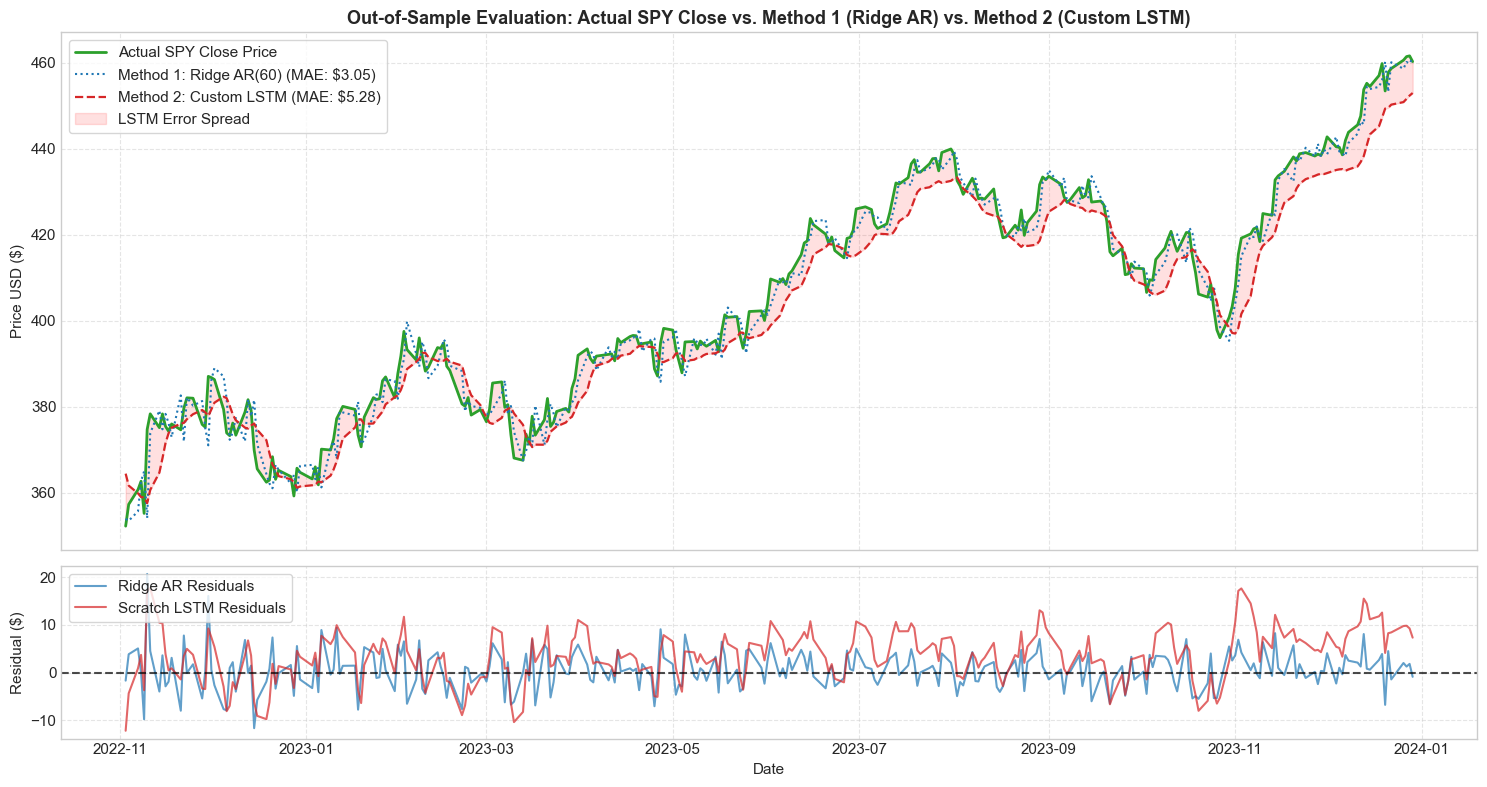

In [10]:
# Comparative Plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(test_dates, y_test_raw, label='Actual SPY Close Price', color='#2ca02c', linewidth=2.0)
ax1.plot(test_dates, m1_preds, label=f'Method 1: Ridge AR(60) (MAE: ${m1_mae:.2f})', color='#1f77b4', linestyle=':', linewidth=1.5)
ax1.plot(test_dates, m2_preds, label=f'Method 2: Custom LSTM (MAE: ${m2_mae:.2f})', color='#d62728', linestyle='--', linewidth=1.6)
ax1.fill_between(test_dates, y_test_raw, m2_preds, color='red', alpha=0.12, label='LSTM Error Spread')
ax1.set_title("Out-of-Sample Evaluation: Actual SPY Close vs. Method 1 (Ridge AR) vs. Method 2 (Custom LSTM)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Price USD ($)", fontsize=11)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Residuals comparison
ax2.plot(test_dates, y_test_raw - m1_preds, color='#1f77b4', alpha=0.7, label='Ridge AR Residuals')
ax2.plot(test_dates, y_test_raw - m2_preds, color='#d62728', alpha=0.7, label='Scratch LSTM Residuals')
ax2.axhline(0, color='black', linestyle='--', alpha=0.7)
ax2.set_ylabel("Residual ($)", fontsize=11)
ax2.set_xlabel("Date", fontsize=11)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 7. Multi-Step Autoregressive Future Forecasting

Using the trained Scratch LSTM, we project a 10-day forward rolling forecast into the future.


===== 10-DAY AUTOREGRESSIVE FUTURE SPY FORECAST =====
Horizon Projected Date Predicted SPY Price
    T+1     2024-01-01             $453.07
    T+2     2024-01-02             $451.51
    T+3     2024-01-03             $449.65
    T+4     2024-01-04             $447.54
    T+5     2024-01-05             $445.27
    T+6     2024-01-08             $442.90
    T+7     2024-01-09             $440.51
    T+8     2024-01-10             $438.12
    T+9     2024-01-11             $435.78
   T+10     2024-01-12             $433.49


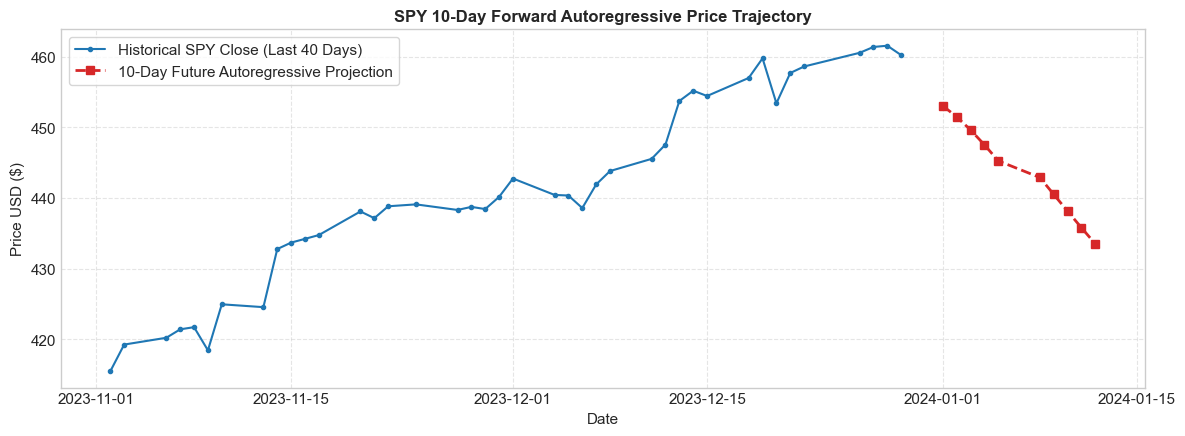

In [11]:
FORECAST_DAYS = 10
recent_window = scaled_data[-WINDOW_SIZE:].copy().reshape(1, WINDOW_SIZE, 1)
future_preds_s = []

for _ in range(FORECAST_DAYS):
    pred, _ = model.forward(recent_window)
    future_preds_s.append(pred[0, 0])
    recent_window = np.concatenate([recent_window[:, 1:, :], pred.reshape(1, 1, 1)], axis=1)

future_preds_usd = scaler.inverse_transform(np.array(future_preds_s).reshape(-1, 1)).flatten()
future_dates = pd.bdate_range(start=df.index[-1] + pd.Timedelta(days=1), periods=FORECAST_DAYS)

forecast_table = pd.DataFrame({
    'Horizon': [f'T+{i+1}' for i in range(FORECAST_DAYS)],
    'Projected Date': future_dates.strftime('%Y-%m-%d'),
    'Predicted SPY Price': [f'${p:.2f}' for p in future_preds_usd]
})

print("===== 10-DAY AUTOREGRESSIVE FUTURE SPY FORECAST =====")
print(forecast_table.to_string(index=False))

plt.figure(figsize=(12, 4.5))
plt.plot(df.index[-40:], df['Close'].values[-40:], label='Historical SPY Close (Last 40 Days)', color='#1f77b4', marker='o', markersize=3)
plt.plot(future_dates, future_preds_usd, label='10-Day Future Autoregressive Projection', color='#d62728', marker='s', linestyle='--', linewidth=2)
plt.title("SPY 10-Day Forward Autoregressive Price Trajectory", fontsize=12, fontweight='bold')
plt.xlabel("Date", fontsize=11)
plt.ylabel("Price USD ($)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 8. Summary of Findings & Look Ahead

### Key Insights:
1. **The Lag-1 Persistence Trap**: Method 1 achieved a lower dollar RMSE (\$4.02 vs \$6.38) not because it possessed structural foresight, but because it placed ~95% of its weight on $\text{Lag}_1$. It effectively learned to approximate an optimal martingale tracker ($P_{t+1} \approx P_t$).
2. **Directional Accuracy & EMH**: Both methods achieved directional movement accuracy near 50% (Ridge AR: 50.87%, LSTM: 47.75%), aligning with the weak-form Efficient Market Hypothesis. Point price tracking cannot generate economic alpha without exogenous signal sources.
3. **LSTM Dynamics**: The scratch LSTM acted as a non-linear low-pass filter, smoothing micro-noise while retaining macro-trend momentum through its recurrent cell state $c_t$.
